SYNTHETIC DATASET - Academic analysis only
Suppliers: (8, 4)
Products: (40, 5)
Orders: (1200, 12)
Inventory: (40, 3)

DATA TYPES
order_id                    object
product_id                  object
order_date          datetime64[ns]
ordered_qty                  int64
supplier_id                 object
base_lead_time               int64
reliability                float64
lead_time_days               int64
received_qty                 int64
delivery_on_time              bool
delivery_status             object
order_value                float64
dtype: object

MISSING VALUES
order_id            0
product_id          0
order_date          0
ordered_qty         0
supplier_id         0
base_lead_time      0
reliability         0
lead_time_days      0
received_qty        0
delivery_on_time    0
delivery_status     0
order_value         0
dtype: int64

DUPLICATE ORDER IDS
0

UNMATCHED PRODUCT ROWS
0

UNMATCHED INVENTORY ROWS
0

SUPPLIER SCORECARD
supplier_id supplier_name  orders_count  avg_le

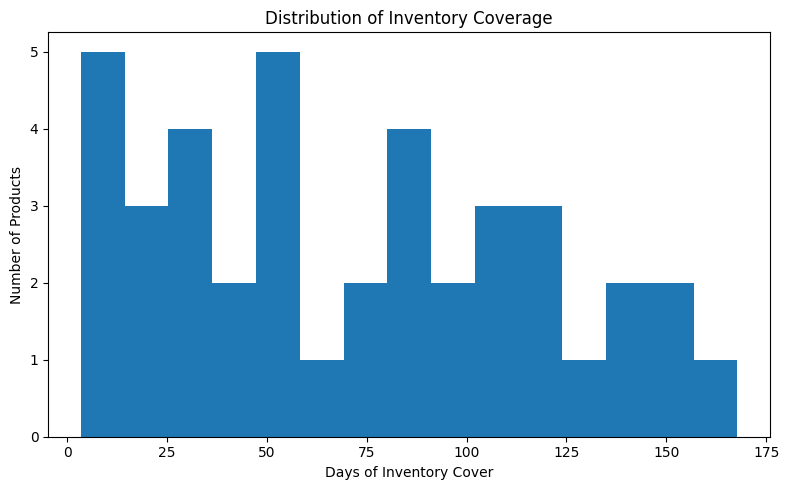

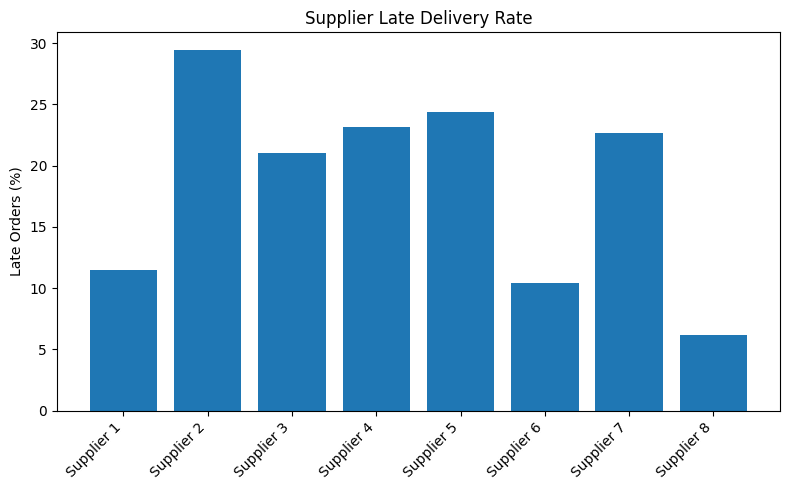

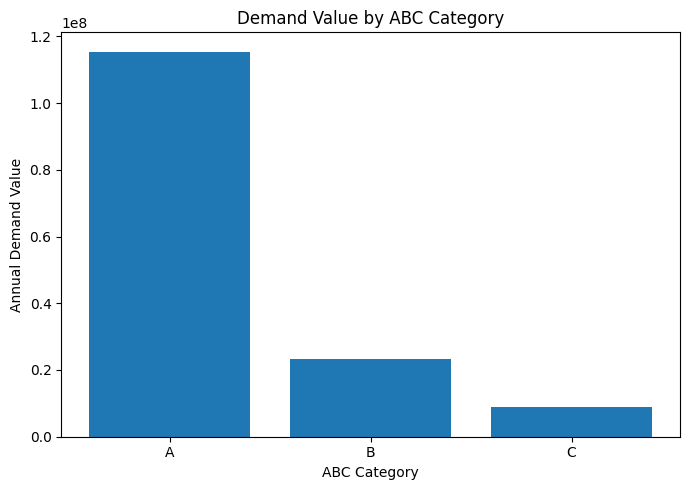

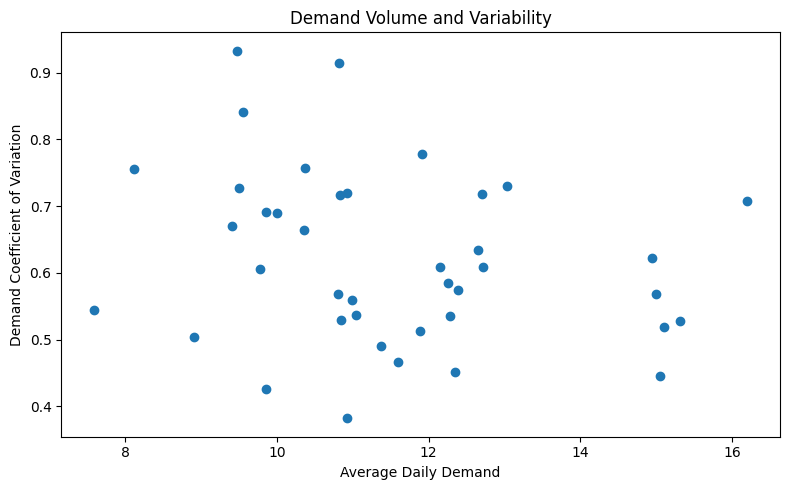

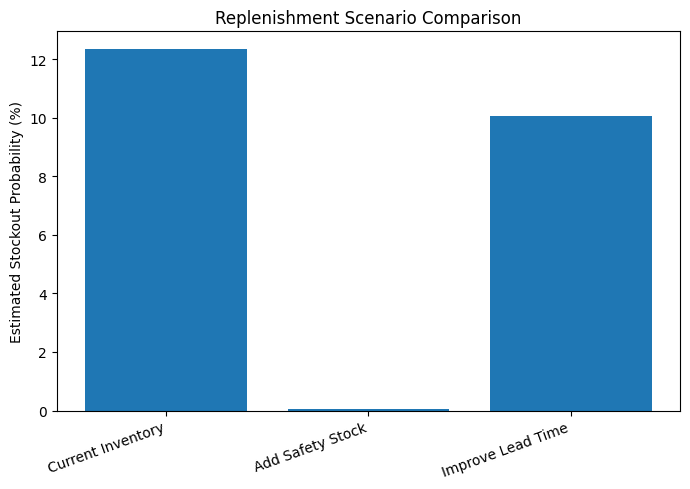


EVIDENCE-BASED FINDINGS
1. The average inventory cover is 71.1 days across all products.
2. 4 products have less than 7 days of inventory cover.
3. 5 products have a simulated stockout probability above 50%.
4. Supplier Supplier 2 has the highest late-delivery rate of 29.4%.
5. ABC category A accounts for 78.2% of the demand value.
6. The mean demand coefficient of variation is 0.62.
7. Adding calculated safety stock changes average simulated stockout risk from 12.3% to 0.0%.
8. The improved lead-time scenario has an average simulated stockout risk of 10.1%.

All CSV files and five chart images have been saved.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

n_products = 40
n_suppliers = 8
n_orders = 1200

supplier_ids = [f"SUP{i:03d}" for i in range(1, n_suppliers + 1)]
product_ids = [f"SKU{i:03d}" for i in range(1, n_products + 1)]

suppliers = pd.DataFrame({
    "supplier_id": supplier_ids,
    "supplier_name": [f"Supplier {i}" for i in range(1, 9)],
    "base_lead_time": np.random.randint(3, 16, n_suppliers),
    "reliability": np.random.uniform(0.72, 0.98, n_suppliers)
})

products = pd.DataFrame({
    "product_id": product_ids,
    "supplier_id": np.random.choice(supplier_ids, n_products),
    "unit_cost": np.round(np.random.uniform(50, 2000, n_products), 2),
    "daily_demand_mean": np.random.uniform(2, 35, n_products),
    "daily_demand_std": np.random.uniform(0.5, 12, n_products)
})

orders = pd.DataFrame({
    "order_id": [f"ORD{i:05d}" for i in range(1, n_orders + 1)],
    "product_id": np.random.choice(product_ids, n_orders),
    "order_date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2025-01-01", "2025-12-31", freq="D"),
            n_orders
        )
    ),
    "ordered_qty": np.random.randint(10, 250, n_orders)
})

orders = orders.merge(
    products[["product_id", "supplier_id"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

orders = orders.merge(
    suppliers[["supplier_id", "base_lead_time", "reliability"]],
    on="supplier_id",
    how="left",
    validate="many_to_one"
)

orders["lead_time_days"] = np.maximum(
    1,
    np.round(
        orders["base_lead_time"] +
        np.random.normal(0, 3, n_orders)
    )
).astype(int)

orders["received_qty"] = np.where(
    np.random.rand(n_orders) < 0.97,
    orders["ordered_qty"],
    np.random.randint(0, 10, n_orders)
)

orders["delivery_on_time"] = (
    np.random.rand(n_orders) < orders["reliability"]
)

orders["delivery_status"] = np.where(
    orders["delivery_on_time"],
    "On Time",
    "Late"
)

orders["order_value"] = (
    orders["ordered_qty"] *
    orders["product_id"].map(
        products.set_index("product_id")["unit_cost"]
    )
)

inventory = pd.DataFrame({
    "product_id": product_ids,
    "current_stock": np.random.randint(0, 1500, n_products),
    "snapshot_date": pd.Timestamp("2025-12-31")
})

print("SYNTHETIC DATASET - Academic analysis only")
print("Suppliers:", suppliers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)
print("Inventory:", inventory.shape)

print("\nDATA TYPES")
print(orders.dtypes)

print("\nMISSING VALUES")
print(orders.isna().sum())

print("\nDUPLICATE ORDER IDS")
print(orders["order_id"].duplicated().sum())

orders = orders.drop_duplicates(subset="order_id")
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["ordered_qty"] = pd.to_numeric(
    orders["ordered_qty"], errors="coerce"
)
orders["lead_time_days"] = pd.to_numeric(
    orders["lead_time_days"], errors="coerce"
)

orders = orders.dropna(
    subset=[
        "order_id", "product_id", "supplier_id",
        "order_date", "ordered_qty", "lead_time_days"
    ]
)

orders = orders[orders["ordered_qty"] > 0]

product_check = orders.merge(
    products,
    on=["product_id", "supplier_id"],
    how="left",
    indicator=True,
    validate="many_to_one"
)

print("\nUNMATCHED PRODUCT ROWS")
print((product_check["_merge"] != "both").sum())

product_check = product_check.drop(columns="_merge")

full_data = product_check.merge(
    inventory,
    on="product_id",
    how="left",
    indicator=True,
    validate="many_to_one"
)

print("\nUNMATCHED INVENTORY ROWS")
print((full_data["_merge"] != "both").sum())

full_data = full_data.drop(columns="_merge")

monthly_demand = orders.groupby(
    ["product_id", pd.Grouper(key="order_date", freq="MS")]
)["ordered_qty"].sum().reset_index()

monthly_demand = monthly_demand.rename(
    columns={
        "order_date": "month",
        "ordered_qty": "monthly_demand"
    }
)

monthly_wide = monthly_demand.pivot_table(
    index="product_id",
    columns="month",
    values="monthly_demand",
    fill_value=0
)

monthly_wide = monthly_wide.reindex(
    product_ids, fill_value=0
)

item_demand = monthly_demand.groupby("product_id").agg(
    total_demand=("monthly_demand", "sum"),
    monthly_mean=("monthly_demand", "mean"),
    monthly_std=("monthly_demand", "std"),
    months_observed=("month", "nunique")
).reset_index()

item_demand["monthly_std"] = item_demand["monthly_std"].fillna(0)

item_demand["demand_cv"] = np.divide(
    item_demand["monthly_std"],
    item_demand["monthly_mean"],
    out=np.zeros(len(item_demand)),
    where=item_demand["monthly_mean"] != 0
)

item_demand["daily_mean"] = item_demand["monthly_mean"] / 30
item_demand["daily_std"] = item_demand["monthly_std"]/ np.sqrt(30)

item_analysis = products.merge(
    item_demand,
    on="product_id",
    how="left",
    validate="one_to_one"
)

item_analysis = item_analysis.merge(
    inventory,
    on="product_id",
    how="left",
    validate="one_to_one"
)

item_analysis["annual_demand_value"] = (
    item_analysis["total_demand"] * item_analysis["unit_cost"]
)

item_analysis["days_of_cover"] = np.divide(
    item_analysis["current_stock"],
    item_analysis["daily_mean"],
    out=np.zeros(len(item_analysis)),
    where=item_analysis["daily_mean"] > 0
)

item_analysis["lead_time_mean"] = (
    orders.groupby("product_id")["lead_time_days"]
    .mean()
    .reindex(item_analysis["product_id"])
    .values
)

item_analysis["lead_time_mean"] = (
    item_analysis["lead_time_mean"].fillna(7)
)

item_analysis["safety_stock"] = (
    1.65 * item_analysis["daily_std"] *
    np.sqrt(item_analysis["lead_time_mean"])
)

item_analysis["reorder_point"] = (
    item_analysis["daily_mean"] *
    item_analysis["lead_time_mean"] +
    item_analysis["safety_stock"]
)

item_analysis["inventory_value"] = (
    item_analysis["current_stock"] *
    item_analysis["unit_cost"]
)

item_analysis = item_analysis.sort_values(
    "annual_demand_value", ascending=False
).reset_index(drop=True)

item_analysis["value_share"] = (
    item_analysis["annual_demand_value"] /
    item_analysis["annual_demand_value"].sum()
)

item_analysis["cumulative_value_share"] = (
    item_analysis["value_share"].cumsum()
)

item_analysis["ABC"] = np.select(
    [
        item_analysis["cumulative_value_share"] <= 0.80,
        item_analysis["cumulative_value_share"] <= 0.95
    ],
    ["A", "B"],
    default="C"
)

item_analysis["XYZ"] = pd.cut(
    item_analysis["demand_cv"],
    bins=[-np.inf, 0.5, 1.0, np.inf],
    labels=["X", "Y", "Z"]
)

item_analysis["ABC_XYZ"] = (
    item_analysis["ABC"].astype(str) +
    item_analysis["XYZ"].astype(str)
)

supplier_metrics = orders.groupby("supplier_id").agg(
    orders_count=("order_id", "count"),
    avg_lead_time=("lead_time_days", "mean"),
    late_orders=("delivery_on_time", lambda x: (~x).sum()),
    avg_order_qty=("ordered_qty", "mean"),
    total_order_value=("order_value", "sum")
).reset_index()

supplier_metrics["late_rate"] = (
    supplier_metrics["late_orders"] /
    supplier_metrics["orders_count"]
)

supplier_metrics = supplier_metrics.merge(
    suppliers,
    on="supplier_id",
    how="left",
    validate="one_to_one"
)

supplier_metrics["reliability_score"] = (
    (1 - supplier_metrics["late_rate"]) * 100
)

simulation_runs = 1000
risk_values = []
scenario_values = []

for row in item_analysis.itertuples():

    mean_daily = max(0, row.daily_mean)
    stock = max(0, int(row.current_stock))
    lead = max(1, int(round(row.lead_time_mean)))

    lead_samples = np.random.randint(
        max(1, lead - 3),
        lead + 4,
        simulation_runs
    )

    demand_samples = np.random.poisson(
        mean_daily * lead_samples
    )

    baseline_risk = np.mean(demand_samples > stock)

    improved_lead = max(1, int(round(lead * 0.8)))

    improved_samples = np.random.poisson(
        mean_daily * improved_lead,
        simulation_runs
    )

    improved_risk = np.mean(improved_samples > stock)

    extra_stock = int(np.ceil(row.safety_stock))

    safety_stock_samples = np.random.poisson(
        mean_daily * lead_samples
    )

    safety_stock_risk = np.mean(
        safety_stock_samples > (stock + extra_stock)
    )

    risk_values.append(baseline_risk)

    scenario_values.append([
        row.product_id,
        baseline_risk,
        safety_stock_risk,
        improved_risk,
        stock,
        extra_stock
    ])

item_analysis["stockout_probability"] = risk_values

scenario_df = pd.DataFrame(
    scenario_values,
    columns=[
        "product_id",
        "baseline_risk",
        "safety_stock_risk",
        "improved_lead_risk",
        "current_stock",
        "extra_safety_stock"
    ]
)

scenario_summary = scenario_df[
    [
        "baseline_risk",
        "safety_stock_risk",
        "improved_lead_risk"
    ]
].mean().reset_index()

scenario_summary.columns = [
    "scenario", "average_stockout_probability"
]

scenario_summary["scenario"] = (
    scenario_summary["scenario"].replace({
        "baseline_risk": "Current Inventory",
        "safety_stock_risk": "Add Safety Stock",
        "improved_lead_risk": "Improve Lead Time"
    })
)

supplier_scorecard = supplier_metrics[
    [
        "supplier_id", "supplier_name", "orders_count",
        "avg_lead_time", "late_orders", "late_rate",
        "reliability_score", "total_order_value"
    ]
].sort_values("late_rate", ascending=False)

priority_actions = item_analysis[
    [
        "product_id", "supplier_id", "ABC_XYZ",
        "current_stock", "days_of_cover",
        "safety_stock", "reorder_point",
        "stockout_probability", "inventory_value"
    ]
].copy()

priority_actions["priority_score"] = (
    priority_actions["stockout_probability"] *
    priority_actions["inventory_value"]
)

priority_actions["recommended_action"] = np.where(
    priority_actions["current_stock"] <
    priority_actions["reorder_point"],
    "Replenish / review",
    "Monitor stock"
)

priority_actions = priority_actions.sort_values(
    "priority_score", ascending=False
)

print("\nSUPPLIER SCORECARD")
print(supplier_scorecard.round(2).to_string(index=False))

print("\nTOP INVENTORY RISKS")
print(priority_actions.head(10).round(2).to_string(index=False))

print("\nSCENARIO COMPARISON")
print(scenario_summary.round(3).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.hist(item_analysis["days_of_cover"], bins=15)
plt.xlabel("Days of Inventory Cover")
plt.ylabel("Number of Products")
plt.title("Distribution of Inventory Coverage")
plt.tight_layout()
plt.savefig("figure_1_inventory_coverage.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(
    supplier_metrics["supplier_name"],
    supplier_metrics["late_rate"] * 100
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Late Orders (%)")
plt.title("Supplier Late Delivery Rate")
plt.tight_layout()
plt.savefig("figure_2_supplier_late_rate.png", dpi=300)
plt.show()

abc_values = item_analysis.groupby(
    "ABC", observed=False
)["annual_demand_value"].sum()

plt.figure(figsize=(7, 5))
plt.bar(abc_values.index.astype(str), abc_values.values)
plt.xlabel("ABC Category")
plt.ylabel("Annual Demand Value")
plt.title("Demand Value by ABC Category")
plt.tight_layout()
plt.savefig("figure_3_abc_demand_value.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(
    item_analysis["daily_mean"],
    item_analysis["demand_cv"]
)
plt.xlabel("Average Daily Demand")
plt.ylabel("Demand Coefficient of Variation")
plt.title("Demand Volume and Variability")
plt.tight_layout()
plt.savefig("figure_4_demand_variability.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
plt.bar(
    scenario_summary["scenario"],
    scenario_summary["average_stockout_probability"] * 100
)
plt.ylabel("Estimated Stockout Probability (%)")
plt.title("Replenishment Scenario Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("figure_5_scenario_comparison.png", dpi=300)
plt.show()

findings = []

findings.append(
    f"The average inventory cover is "
    f"{item_analysis['days_of_cover'].mean():.1f} days across all products."
)

findings.append(
    f"{(item_analysis['days_of_cover'] < 7).sum()} products "
    f"have less than 7 days of inventory cover."
)

findings.append(
    f"{(item_analysis['stockout_probability'] > 0.5).sum()} products "
    f"have a simulated stockout probability above 50%."
)

findings.append(
    f"Supplier {supplier_metrics.loc[supplier_metrics['late_rate'].idxmax(), 'supplier_name']} "
    f"has the highest late-delivery rate of "
    f"{supplier_metrics['late_rate'].max():.1%}."
)

findings.append(
    f"ABC category A accounts for "
    f"{abc_values.get('A', 0) / max(abc_values.sum(), 1) * 100:.1f}% "
    f"of the demand value."
)

findings.append(
    f"The mean demand coefficient of variation is "
    f"{item_analysis['demand_cv'].mean():.2f}."
)

findings.append(
    f"Adding calculated safety stock changes average simulated stockout risk "
    f"from {scenario_summary.iloc[0]['average_stockout_probability']:.1%} "
    f"to {scenario_summary.loc[scenario_summary['scenario'] == 'Add Safety Stock', 'average_stockout_probability'].iloc[0]:.1%}."
)

findings.append(
    f"The improved lead-time scenario has an average simulated stockout risk of "
    f"{scenario_summary.loc[scenario_summary['scenario'] == 'Improve Lead Time', 'average_stockout_probability'].iloc[0]:.1%}."
)

print("\nEVIDENCE-BASED FINDINGS")

for i, finding in enumerate(findings, 1):
    print(f"{i}. {finding}")

orders.to_csv("cleaned_orders.csv", index=False)
item_analysis.to_csv("item_risk_analysis.csv", index=False)
supplier_scorecard.to_csv("supplier_scorecard.csv", index=False)
priority_actions.to_csv("priority_actions.csv", index=False)
scenario_summary.to_csv("scenario_comparison.csv", index=False)
monthly_demand.to_csv("monthly_demand.csv", index=False)

print("\nAll CSV files and five chart images have been saved.")

In [3]:
import os
import zipfile
from google.colab import files

project_files = [
    "cleaned_orders.csv",
    "item_risk_analysis.csv",
    "supplier_scorecard.csv",
    "priority_actions.csv",
    "scenario_comparison.csv",
    "monthly_demand.csv",
    "figure_1_inventory_coverage.png",
    "figure_2_supplier_late_rate.png",
    "figure_3_abc_demand_value.png",
    "figure_4_demand_variability.png",
    "figure_5_scenario_comparison.png"
]

with zipfile.ZipFile("Supply_Chain_Project_Results.zip", "w") as zip_file:
    for file in project_files:
        if os.path.exists(file):
            zip_file.write(file)

files.download("Supply_Chain_Project_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>